In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
df_encoded = pd.read_csv(r"D:\Sasi\GUVI HCL AI-ML\Credit_Segmentation_Project\dataset\cleaned\featured_loans_granting_model_dataset.csv")
print(f"Loaded dataset shape: {df_encoded.shape}")

Loaded dataset shape: (1347147, 34)


In [4]:
numerical_features = ['revenue_log', 'dti_n', 'loan_amnt', 'fico_n', 'emp_length_n']
encoded_cat_features = [col for col in df_encoded.columns if col.startswith(('purpose_', 'home_ownership_n_'))]
all_model_features = numerical_features + encoded_cat_features

X_raw = df_encoded[all_model_features]

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

pca = PCA(n_components=10, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"PCA reduced feature shape: {X_pca.shape}")
print(f"Explained variance ratio sum by top 10 components: {pca.explained_variance_ratio_.sum():.4f}")

PCA reduced feature shape: (1347147, 10)
Explained variance ratio sum by top 10 components: 0.5844


In [6]:
# t-SNE is computationally expensive on 1.34M rows, so we sample 5,000 points while maintaining default proportions
df_sample = df_encoded.groupby('Default', group_keys=False).apply(lambda x: x.sample(n=int(5000 * len(x) / len(df_encoded)), random_state=42)).reset_index(drop=True)

X_sample_raw = df_sample[all_model_features]
X_sample_scaled = scaler.transform(X_sample_raw)
X_sample_pca = pca.transform(X_sample_scaled)

C:\Users\ssasi\AppData\Local\Temp\ipykernel_23480\1756246237.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_encoded.groupby('Default', group_keys=False).apply(lambda x: x.sample(n=int(5000 * len(x) / len(df_encoded)), random_state=42)).reset_index(drop=True)


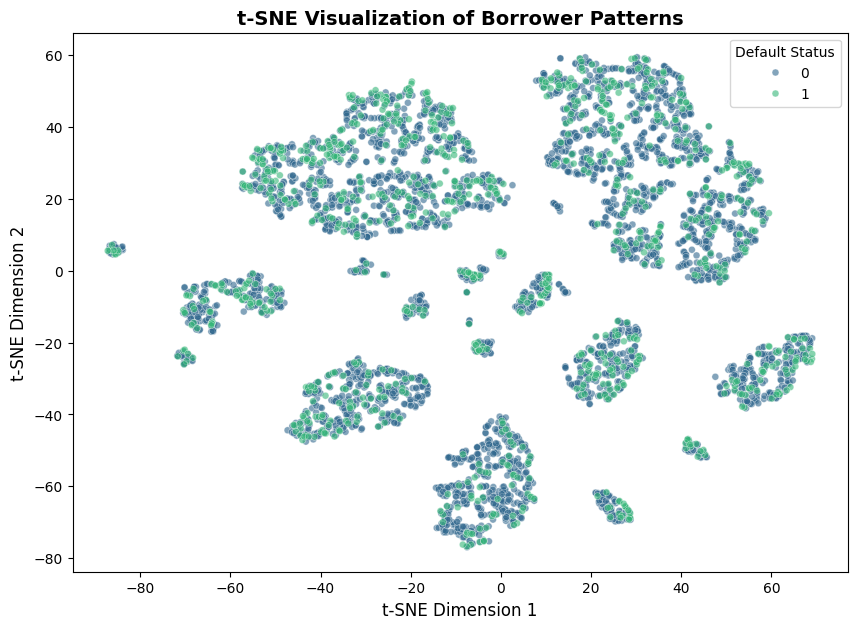

In [10]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_sample_pca)

df_sample['tsne_1'] = X_tsne[:, 0]
df_sample['tsne_2'] = X_tsne[:, 1]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_sample,x='tsne_1',y='tsne_2',hue='Default',palette='viridis',alpha=0.6,s=25)
plt.title('t-SNE Visualization of Borrower Patterns', fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=12)
plt.ylabel('t-SNE Dimension 2', fontsize=12)
plt.legend(title='Default Status')
plt.show()

In [12]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [23]:
print("\n--- Running K-Means Clustering ---")
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

df_encoded['KMeans_Cluster'] = kmeans_labels
print(f"K-Means completed. Cluster distribution:\n{df_encoded['KMeans_Cluster'].value_counts()}")

km_silhouette = silhouette_score(X_pca, kmeans_labels, sample_size=2000, random_state=42)
km_davies = davies_bouldin_score(X_pca, kmeans_labels)
print(f"K-Means Silhouette Score (higher is better): {km_silhouette:.4f}")
print(f"K-Means Davies-Bouldin Index (lower is better): {km_davies:.4f}")


--- Running K-Means Clustering ---
K-Means completed. Cluster distribution:
KMeans_Cluster
2    839277
1    375893
0    100035
3     31942
Name: count, dtype: int64
K-Means Silhouette Score (higher is better): 0.3216
K-Means Davies-Bouldin Index (lower is better): 1.4406


In [16]:
print("\n--- Creating Stratified Sample for Hierarchical & DBSCAN ---")
df_10ksample = df_encoded.groupby('Default', group_keys=False).apply(lambda x: x.sample(n=int(10000 * len(x) / len(df_encoded)), random_state=42)).reset_index(drop=True)

X_10ksample_pca = pca.transform(scaler.transform(df_sample[all_model_features]))


--- Creating Stratified Sample for Hierarchical & DBSCAN ---


C:\Users\ssasi\AppData\Local\Temp\ipykernel_23480\2295194011.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_10ksample = df_encoded.groupby('Default', group_keys=False).apply(lambda x: x.sample(n=int(10000 * len(x) / len(df_encoded)), random_state=42)).reset_index(drop=True)


In [18]:
print("\n--- Running Hierarchical Clustering ---")
hierarchical = AgglomerativeClustering(n_clusters=4)
hier_labels = hierarchical.fit_predict(X_10ksample_pca)
df_10ksample['Hierarchical_Cluster'] = hier_labels

# Evaluate Hierarchical Quality
print("Hierarchical Silhouette Score:", silhouette_score(X_10ksample_pca, hier_labels, sample_size=2000))


--- Running Hierarchical Clustering ---
Hierarchical Silhouette Score: 0.329786077168559


In [19]:
print("\n--- Running DBSCAN Clustering ---")
dbscan = DBSCAN(eps=1.8, min_samples=15)
dbscan_labels = dbscan.fit_predict(X_10ksample_pca)
df_10ksample['DBSCAN_Cluster'] = dbscan_labels

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
print(f"DBSCAN detected {n_clusters_db} clusters and noise points (labeled as -1).")
if n_clusters_db > 1:
    print("DBSCAN Silhouette Score:", silhouette_score(X_10ksample_pca, dbscan_labels, sample_size=2000))


--- Running DBSCAN Clustering ---
DBSCAN detected 9 clusters and noise points (labeled as -1).
DBSCAN Silhouette Score: 0.4064781487310374


In [22]:
anomalies = df_10ksample[df_10ksample['DBSCAN_Cluster'] == -1]
normal_borrowers = df_10ksample[df_10ksample['DBSCAN_Cluster'] != -1]

print(f"Total evaluated borrowers in sample: {len(df_10ksample)}")
print(f"Number of unusual borrower profiles (Anomalies) detected: {len(anomalies)}")

# Compare financial metrics between Normal Borrowers and Anomalies
anomaly_profile = pd.DataFrame({
    'Metric': ['Mean Loan Amount', 'Mean FICO', 'Mean DTI', 'Mean Revenue', 'Default Rate (%)'],
    'Normal Borrowers': [
        normal_borrowers['loan_amnt'].mean(),
        normal_borrowers['fico_n'].mean(),
        normal_borrowers['dti_n'].mean(),
        normal_borrowers['revenue'].mean(),
        normal_borrowers['Default'].mean() * 100
    ],
    'Anomalies (Outliers)': [
        anomalies['loan_amnt'].mean(),
        anomalies['fico_n'].mean(),
        anomalies['dti_n'].mean(),
        anomalies['revenue'].mean(),
        anomalies['Default'].mean() * 100
    ]
})

print("\n--- Anomaly Profiling Comparison ---")
print(anomaly_profile.to_string(index=False))

Total evaluated borrowers in sample: 9999
Number of unusual borrower profiles (Anomalies) detected: 87

--- Anomaly Profiling Comparison ---
          Metric  Normal Borrowers  Anomalies (Outliers)
Mean Loan Amount      14500.416162          12170.689655
       Mean FICO        697.823799            709.643678
        Mean DTI         18.233769             16.089195
    Mean Revenue      77890.566994         105347.360690
Default Rate (%)         19.995964             17.241379


In [20]:
print("\n--- Profiling K-Means Clusters against Financial Characteristics & Default Rate ---")

# Merge cluster labels back with original unscaled numerical features for business interpretation
profile_features = ['loan_amnt', 'fico_n', 'dti_n', 'revenue', 'emp_length_n', 'Default', 'KMeans_Cluster']
cluster_profile = df_encoded[profile_features].groupby('KMeans_Cluster').mean()

# Add loan count per cluster
cluster_profile['Total_Borrowers'] = df_encoded['KMeans_Cluster'].value_counts()
cluster_profile['Default_Rate (%)'] = df_encoded.groupby('KMeans_Cluster')['Default'].mean() * 100

print(cluster_profile[['Total_Borrowers', 'Default_Rate (%)', 'loan_amnt', 'fico_n', 'dti_n', 'revenue']])


--- Profiling K-Means Clusters against Financial Characteristics & Default Rate ---
                Total_Borrowers  Default_Rate (%)     loan_amnt      fico_n  \
KMeans_Cluster                                                                
0                        100035         18.169641  13408.822912  706.006513   
1                        375893         17.820231  13703.264759  697.789785   
2                        839277         20.965426  14897.485365  697.129268   
3                         31942         25.004696  12884.167397  704.905094   

                    dti_n       revenue  
KMeans_Cluster                           
0               15.922162  90309.186115  
1               18.085802  75945.301879  
2               18.631073  76171.638160  
3               15.393264  84349.812154  


In [21]:
# Default pattern analysis
default_pattern = df_encoded.groupby('KMeans_Cluster')['Default'].agg(
    Total_Borrowers='count',
    Default_Count='sum',
    Default_Rate_Pct=lambda x: (x.sum() / x.count()) * 100
).reset_index()

print("Default Pattern Analysis across Unsupervised Clusters:")
print(default_pattern.to_string(index=False))

Default Pattern Analysis across Unsupervised Clusters:
 KMeans_Cluster  Total_Borrowers  Default_Count  Default_Rate_Pct
              0           100035          18176         18.169641
              1           375893          66985         17.820231
              2           839277         175958         20.965426
              3            31942           7987         25.004696
